# 📘 Apunte: Métodos de Ensamble
**Minería de Datos y Aprendizaje Automático** — Dataset de trabajo: `diabetes.csv`

### Índice
1. ¿Qué es un ensamble?
2. Carga de datos
3. **Bagging** → Random Forest
4. **Boosting** → AdaBoost, Gradient Boosting, XGBoost, LightGBM
5. **Stacking** (y stacking de varias capas)
6. Comparación de todos los modelos (10 repeticiones + IC 95%)
7. Actividad 2 (dataset *glass*)
8. Resumen para repasar

# 1. ¿Qué es un ensamble?

Un **ensamble** es un **conjunto de modelos** (llamados **estimadores base**) que **todos juntos** aportan a la predicción.

Ejemplo de la clase: 5 clasificadores predicen sobre la misma muestra → se **cuentan los votos** → gana la clase más votada.

```
Clasificador 1 → Clase 2 ┐
Clasificador 2 → Clase 1 │
Clasificador 3 → Clase 2 ├─► Conteo ─► Clase 1  (3 votos contra 2)
Clasificador 4 → Clase 1 │
Clasificador 5 → Clase 1 ┘
```

**¿Por qué sirve?** Cada modelo solo se equivoca en algunos casos. Si se equivocan en casos **distintos**, al votar los errores se compensan.

**Ventajas:**
- Reducen el error en la predicción.
- Mantienen una buena generalización (no se "aprenden de memoria" el train).

### Los 3 tipos que vemos
| Tipo | ¿Cómo entrena? | Ejemplos |
|---|---|---|
| **Bagging** | Muchos modelos **en paralelo**, cada uno con una parte distinta de los datos. Luego votan. | Random Forest |
| **Boosting** | Modelos **uno después del otro**; cada uno corrige los errores del anterior. | AdaBoost, Gradient Boosting, XGBoost |
| **Stacking** | Modelos **de distinto tipo** + un **meta-modelo** que aprende a combinarlos. | StackingClassifier |

# 2. Carga de datos

In [1]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y MÓDULOS
# ==============================================================================

# Manejo y manipulación de datos en tablas (DataFrames)
import pandas as pd

# Visualización gráfica de datos (gráficos estadísticos, matriz de confusión)
import seaborn as sns
import matplotlib.pyplot as plt

# Montaje de Google Drive para acceder a archivos almacenados en la nube
from google.colab import drive
drive.mount('/content/drive')

# División de datos en conjuntos de entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Algoritmos de Machine Learning (Árbol de Decisión y Random Forest)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas de evaluación para modelos de clasificación
from sklearn import metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)


In [2]:
from google.colab import drive
drive.mount('/content/drive')
from typing_extensions import Reader
import pandas as pd
df=pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/datasets/diabetes.csv")


In [3]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")   # oculta avisos que no afectan al resultado

print("Filas y columnas:", df.shape)
print("\nCantidad por clase (Outcome: 1 = diabetes, 0 = no):")
print(df["Outcome"].value_counts())
df.head()

Filas y columnas: (768, 9)

Cantidad por clase (Outcome: 1 = diabetes, 0 = no):
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Separamos **X** (atributos) y **T** (target) y dividimos en **90% train / 10% test**.
Esta división la usamos en todos los ejemplos del apunte.

In [4]:
feature_cols = df.columns[:-1]      # todas las columnas menos Outcome
X = df[feature_cols]
T = df.Outcome

X_train, X_test, T_train, T_test = train_test_split(X, T, test_size=0.1, random_state=13)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (691, 8) | Test: (77, 8)


# 3. Bagging

**Bagging** = entrenar **N estimadores** del mismo tipo, cada uno con una **muestra distinta** del dataset. La predicción final es **la respuesta más votada**.

¿Cómo se arma cada muestra?
| Técnica | Qué se elige al azar | ¿Con reemplazo? |
|---|---|---|
| **Bootstrapping** | Filas | Sí (una fila puede repetirse) |
| **Pasting** | Filas | No |
| **Random subspace** | Columnas (atributos) | — |

Como cada modelo ve datos un poco distintos, los modelos salen distintos y sus errores se compensan al votar.

In [5]:
# Ejemplo con 10 filas: así se ve el bootstrapping
np.random.seed(0)
filas = np.arange(10)
print("Dataset original:", filas)
for i in range(3):
    muestra = np.random.choice(filas, size=10, replace=True)   # CON reemplazo
    no_elegidas = np.setdiff1d(filas, muestra)
    print(f"Modelo {i+1} entrena con {np.sort(muestra)}  -> quedaron afuera: {no_elegidas}")

print("\nPasting (SIN reemplazo, 7 filas):", np.sort(np.random.choice(filas, size=7, replace=False)))

Dataset original: [0 1 2 3 4 5 6 7 8 9]
Modelo 1 entrena con [0 2 3 3 3 4 5 5 7 9]  -> quedaron afuera: [1 6 8]
Modelo 2 entrena con [1 1 6 6 7 7 7 8 8 8]  -> quedaron afuera: [0 2 3 4 5 9]
Modelo 3 entrena con [0 0 3 3 4 5 5 8 9 9]  -> quedaron afuera: [1 2 6 7]

Pasting (SIN reemplazo, 7 filas): [1 4 5 6 7 8 9]


> Dato: con bootstrapping cada modelo ve aproximadamente el **63%** de las filas. El **37%** que queda afuera (*out-of-bag*, OOB) se puede usar para evaluar el modelo sin usar el test.

### Bagging en código
`BaggingClassifier` permite elegir la técnica con sus parámetros:

In [6]:
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score

variantes = {
    # bootstrap=True -> filas con reemplazo
    "Bootstrapping": BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                                       bootstrap=True, random_state=13),
    # bootstrap=False + max_samples -> filas sin reemplazo (70%)
    "Pasting": BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                                 bootstrap=False, max_samples=0.7, random_state=13),
    # max_features -> cada modelo usa solo el 50% de las columnas
    "Random subspace": BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                                         bootstrap=False, max_features=0.5, random_state=13),
}

arbol = DecisionTreeClassifier(random_state=13).fit(X_train, T_train)
print(f"{'1 solo árbol':16s} accuracy = {accuracy_score(T_test, arbol.predict(X_test)):.3f}")
for nombre, modelo in variantes.items():
    modelo.fit(X_train, T_train)
    print(f"{nombre:16s} accuracy = {accuracy_score(T_test, modelo.predict(X_test)):.3f}")

1 solo árbol     accuracy = 0.675


Bootstrapping    accuracy = 0.740


Pasting          accuracy = 0.714


Random subspace  accuracy = 0.805


# BAGGING
## RANDOM FOREST

**Random Forest** es un bagging de **árboles de decisión**:
- Es un ensamble de **N árboles independientes**.
- Cada árbol se construye con **distintas muestras** (bootstrapping) **y distintos atributos** (en cada nodo solo puede elegir entre algunos atributos sorteados).
- La predicción se hace por **votación**.

**Ejemplo de la clase:** un animal con Peso 6000 gr, Salto 180 cm, Dientes 28, Comida 350 gr.
6 árboles votan: Gato, Perro, Gato, Gato, Gato, Gato → **Gato con 5/6 de los votos**.

Ese "5/6" es lo que devuelve `predict_proba`: la **proporción de votos** de cada clase.

In [7]:
from sklearn.ensemble import RandomForestClassifier

# Selecciono mis columnas de features
feature_cols = df.columns[:-1]
X = df[feature_cols]

# Seleccion mi columna objetivo
T = df.Outcome

# Separo dataset entrenamientos / Test
X_train, X_test, T_train, T_test = train_test_split(X, T, test_size=0.1, random_state=13)  # 90% train / 10% test

# Cargo algoritmo de Random Forest
rf = RandomForestClassifier(n_estimators = 1000)

# Entreno mi modelo
model = rf.fit(X_train, T_train)
T_pred = model.predict(X_test)

# Saco los estimadores de cada árbol
e = rf.estimators_[0] # permite obtener los árboles (zero-based),

# devuelve la proporción de votos
print(model.predict_proba(X_test))

[[0.598 0.402]
 [0.83  0.17 ]
 [0.86  0.14 ]
 [0.563 0.437]
 [0.483 0.517]
 [0.988 0.012]
 [0.962 0.038]
 [0.947 0.053]
 [0.877 0.123]
 [0.379 0.621]
 [0.717 0.283]
 [0.639 0.361]
 [0.878 0.122]
 [0.322 0.678]
 [0.994 0.006]
 [0.396 0.604]
 [0.927 0.073]
 [0.453 0.547]
 [0.271 0.729]
 [0.706 0.294]
 [0.613 0.387]
 [0.731 0.269]
 [0.542 0.458]
 [0.736 0.264]
 [0.908 0.092]
 [0.67  0.33 ]
 [0.222 0.778]
 [0.851 0.149]
 [0.454 0.546]
 [0.264 0.736]
 [0.237 0.763]
 [0.894 0.106]
 [0.558 0.442]
 [0.455 0.545]
 [0.896 0.104]
 [0.534 0.466]
 [0.348 0.652]
 [0.614 0.386]
 [0.989 0.011]
 [0.94  0.06 ]
 [0.705 0.295]
 [0.731 0.269]
 [0.826 0.174]
 [0.85  0.15 ]
 [0.635 0.365]
 [0.576 0.424]
 [0.315 0.685]
 [0.713 0.287]
 [0.746 0.254]
 [0.645 0.355]
 [0.44  0.56 ]
 [0.661 0.339]
 [0.772 0.228]
 [0.926 0.074]
 [0.17  0.83 ]
 [0.988 0.012]
 [0.733 0.267]
 [0.506 0.494]
 [0.534 0.466]
 [0.923 0.077]
 [0.943 0.057]
 [0.911 0.089]
 [0.689 0.311]
 [0.236 0.764]
 [0.118 0.882]
 [0.306 0.694]
 [0.457 0.

In [8]:
# ¿Mejora respecto de un solo árbol?
print("Accuracy 1 árbol      :", round(accuracy_score(T_test, arbol.predict(X_test)), 3))
print("Accuracy Random Forest:", round(accuracy_score(T_test, T_pred), 3))

# Cómo leer predict_proba: [proporción que votó 0, proporción que votó 1]
proba = model.predict_proba(X_test)
for i in range(3):
    print(f"Paciente {i}: {proba[i][0]:.0%} de los árboles dice 'sin diabetes', "
          f"{proba[i][1]:.0%} dice 'diabetes' -> predicción: {T_pred[i]}")

Accuracy 1 árbol      : 0.675
Accuracy Random Forest: 0.766
Paciente 0: 60% de los árboles dice 'sin diabetes', 40% dice 'diabetes' -> predicción: 0
Paciente 1: 83% de los árboles dice 'sin diabetes', 17% dice 'diabetes' -> predicción: 0
Paciente 2: 86% de los árboles dice 'sin diabetes', 14% dice 'diabetes' -> predicción: 0


### Ver uno de los árboles del bosque (`rf.estimators_[i]`)

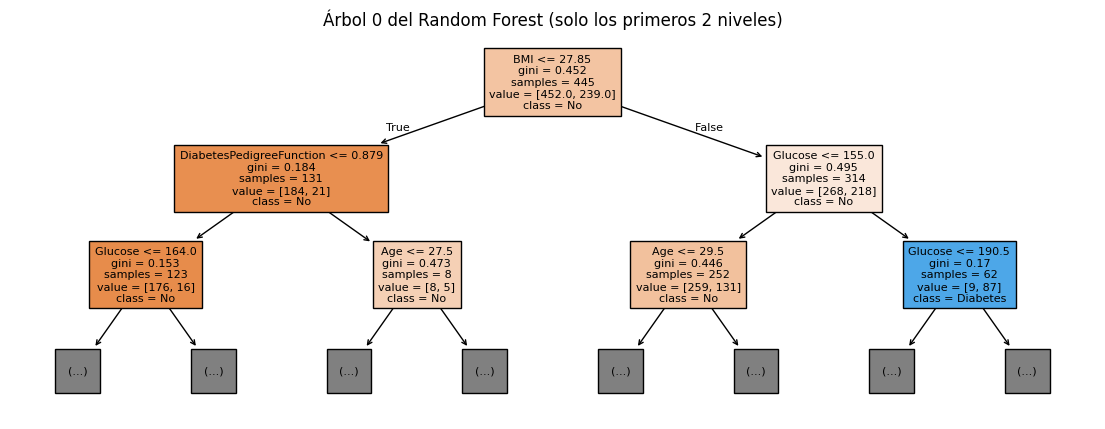

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

e = rf.estimators_[0]    # el primer árbol (se cuenta desde 0)
plt.figure(figsize=(14, 5))
plot_tree(e, max_depth=2, feature_names=feature_cols, class_names=["No", "Diabetes"], filled=True, fontsize=8)
plt.title("Árbol 0 del Random Forest (solo los primeros 2 niveles)")
plt.show()

### ¿Qué atributos usó más el bosque?

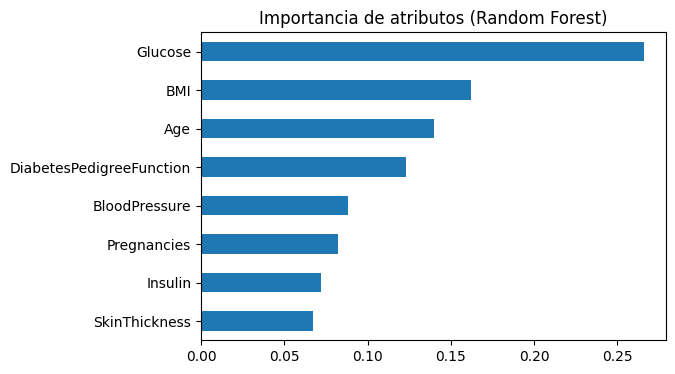

In [10]:
importancias = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
importancias.plot.barh(figsize=(6, 4), title="Importancia de atributos (Random Forest)")
plt.show()

**Parámetros principales de `RandomForestClassifier`:**
| Parámetro | Para qué sirve |
|---|---|
| `n_estimators` | Cantidad de árboles. Más árboles **no** empeora el modelo, solo tarda más. |
| `max_features` | Cuántos atributos puede elegir cada nodo (default `"sqrt"`). |
| `max_depth` | Profundidad máxima de cada árbol. |
| `oob_score=True` | Evalúa con las filas que quedaron afuera del bootstrapping. |

# Boosting

El objetivo es usar varios modelos **“débiles”** para lograr
un modelo **“fuerte”** que tenga un error mínimo.
La forma de armar los modelos es secuencial, uno tras
otro, de tal manera que al entrenar un modelo, éste
toma en cuenta los errores de su predecesor.
- AdaBoost
- Gradient Boosting
- XGBoost

**Modelo "débil":** un modelo muy simple, que acierta apenas más que el azar. El típico es un árbol de **un solo nivel** (una sola pregunta, llamado *stump*).

**Diferencia con Bagging:**
| | Bagging | Boosting |
|---|---|---|
| Orden | Todos a la vez (paralelo) | Uno después del otro (secuencial) |
| Cada modelo... | No sabe nada de los demás | Aprende de los errores del anterior |
| Corrige | Modelos que sobreajustan | Modelos demasiado simples |

## AdaBoost (Adaptative boosting)

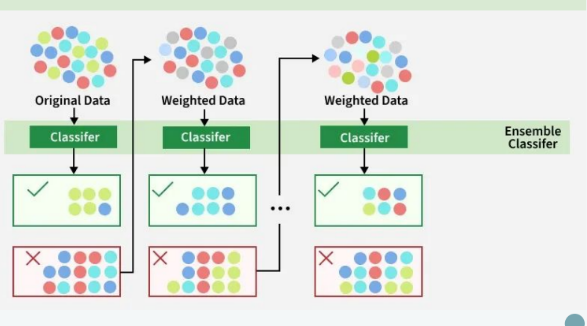

Al comienzo todas las muestras tienen el mismo “peso”.
Se entrena un primer modelo, el cual clasificará correctamente algunas muestras,
mientras que otras no.
Las muestras mal clasificadas aumentan su “peso”.
El siguiente modelo a entrenar recibe
las mismas muestras, con los pesos
modificados.

### Paso a paso
1. Al comienzo **todas las muestras pesan igual**.
2. Se entrena un modelo débil. Acierta algunas muestras y falla en otras.
3. Se calcula su **error** (suma de los pesos de las muestras mal clasificadas).
4. Se le da un **puntaje de importancia α**: si tuvo poco error, α es alto.
   $$\alpha = \ln\left(\frac{1 - \text{error}}{\text{error}}\right)$$
5. Las muestras **mal clasificadas aumentan su peso**, para que el siguiente modelo les preste más atención.
6. Se repite un número prefijado de veces.

**Predicción:** cada modelo vota, pero su voto vale según su α:
$$\text{voto} = \sum \alpha \cdot \text{pred}_i(X)$$

### Lo hacemos a mano (3 rondas) para ver cómo cambian los pesos

In [11]:
n = len(T_train)
pesos = np.ones(n) / n                      # 1) todos los pesos iguales
y = T_train.values

for ronda in range(1, 4):
    stump = DecisionTreeClassifier(max_depth=1).fit(X_train, y, sample_weight=pesos)   # 2) modelo débil
    mal = stump.predict(X_train) != y                                                  # mal clasificadas
    error = pesos[mal].sum()                                                           # 3) error
    alpha = np.log((1 - error) / error)                                                # 4) importancia
    pesos[mal] = pesos[mal] * np.exp(alpha)                                            # 5) suben las mal clasificadas
    pesos = pesos / pesos.sum()                                                        #    (se normaliza)

    pregunta = feature_cols[stump.tree_.feature[0]]
    print(f"Ronda {ronda}: pregunta sobre '{pregunta}' | mal clasificadas: {mal.sum()} | "
          f"error = {error:.3f} | alpha = {alpha:.3f}")
    print(f"          las mal clasificadas pesaban el {error:.0%} del total -> ahora pesan el {pesos[mal].sum():.0%}")

Ronda 1: pregunta sobre 'Glucose' | mal clasificadas: 187 | error = 0.271 | alpha = 0.991
          las mal clasificadas pesaban el 27% del total -> ahora pesan el 50%
Ronda 2: pregunta sobre 'Age' | mal clasificadas: 240 | error = 0.356 | alpha = 0.594
          las mal clasificadas pesaban el 36% del total -> ahora pesan el 50%
Ronda 3: pregunta sobre 'BMI' | mal clasificadas: 317 | error = 0.375 | alpha = 0.512
          las mal clasificadas pesaban el 37% del total -> ahora pesan el 50%


### AdaBoost con scikit-learn

In [12]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Definición del estimador base (clasificador débil)
# Por defecto, DecisionTreeClassifier tiene max_depth=1 (árbol de 1 solo corte o "stump")
base = DecisionTreeClassifier(max_depth=1)

# 2. Configuración del ensamble AdaBoost
# 'estimator': el modelo base que se entrenará iterativamente.
# 'n_estimators': número máximo de estimadores a entrenar secuencialmente.
ada = AdaBoostClassifier(estimator=base, n_estimators=500, random_state=42)

# 3. Entrenamiento del modelo
model = ada.fit(X_train, T_train)

# 4. Inspección de los pesos de cada estimador (alpha)
# Asigna mayor peso a los árboles que tuvieron menor tasa de error
print("Pesos de cada estimador (alphas):")
print(model.estimator_weights_)

# 5. Obtención de probabilidades de predicción
# Devuelve las probabilidades estimadas para cada clase en el conjunto de prueba
print("\nProbabilidades de clase para X_test:")
print(model.predict_proba(X_test))



Pesos de cada estimador (alphas):
[0.99146765 0.59356817 0.51196685 0.53323515 0.63406209 0.33742492
 0.27658426 0.18122462 0.35821332 0.28774929 0.24997428 0.11597022
 0.14579652 0.26378805 0.11071285 0.21272761 0.15478389 0.18224209
 0.14921739 0.20821302 0.11524758 0.14709555 0.13284278 0.10385413
 0.06072744 0.05820716 0.05583889 0.05360886 0.07886424 0.18351331
 0.14930612 0.16686933 0.15266601 0.12190666 0.0567183  0.05442003
 0.05225366 0.05020788 0.04827268 0.05158692 0.1125341  0.1527172
 0.08012116 0.11474902 0.10808116 0.04495915 0.04938593 0.04735352
 0.03288746 0.03221597 0.04546962 0.04364466 0.04288887 0.04133542
 0.0530969  0.0799503  0.05870318 0.0920779  0.09793998 0.06266444
 0.0254479  0.08619561 0.05795798 0.04948138 0.071346   0.07298259
 0.05821723 0.05431487 0.04725574 0.05647261 0.09357182 0.08894739
 0.05433136 0.06458798 0.06745094 0.10847073 0.16235579 0.17239539
 0.15912925 0.17830392 0.1494586  0.06883939 0.07840971 0.02760875
 0.0387659  0.08651525 0.1191

In [13]:
print("Accuracy AdaBoost:", round(accuracy_score(T_test, model.predict(X_test)), 3))

Accuracy AdaBoost: 0.766


⚠️ **Ojo con el código de la diapositiva:** usa `DecisionTreeClassifier()` sin límite de profundidad.
Un árbol completo **acierta todo el train** → error = 0 → no hay nada que corregir → **AdaBoost se detiene en el primer árbol**.
Por eso hay que usar modelos **débiles** (`max_depth=1` o `2`).

In [14]:
ada_completo = AdaBoostClassifier(estimator=DecisionTreeClassifier(), n_estimators=500, random_state=42)
ada_completo.fit(X_train, T_train)
print("Árboles entrenados con árbol completo:", len(ada_completo.estimators_))
print("Árboles entrenados con max_depth=1   :", len(model.estimators_))

Árboles entrenados con árbol completo: 1
Árboles entrenados con max_depth=1   : 500


**Parámetros principales de `AdaBoostClassifier`:**
| Parámetro | Para qué sirve |
|---|---|
| `estimator` | El modelo débil (ej. `DecisionTreeClassifier(max_depth=1)`). |
| `n_estimators` | Cuántos modelos se entrenan en secuencia. |
| `learning_rate` | Achica el α de cada modelo. Si es más chico, hacen falta más modelos. |

**Gradient Boosting**

Se entrena un primer modelo (por lo general árboles de decisión), el cual cometerá
errores en la clasificación.
Para cada muestra se calcula el “residuo”, que es el error (numérico) que cometió el
estimador al hacer la predicción.
Los siguientes modelos “débiles” intentarán
predecir esos “residuos”.
Se continúa de la misma manera un número
prefijado de pasos.
El resultado es un modelo ensemble “fuerte”.

¿Cómo funciona paso a paso?
- Paso 1: Se crea un modelo base inicial muy simple (por ejemplo, predecir el promedio de todos los datos).
- Paso 2: Se calculan los errores (la diferencia entre lo real y lo que predijo el modelo).
- Paso 3: Se entrena un nuevo árbol de decisión, pero no para predecir el resultado final, sino para predecir los errores del paso anterior.
- Paso 4: Se suma este nuevo árbol al modelo general para corregir el tiro.
- Paso 5: Se repite el proceso decenas o cientos de veces hasta que los errores sean mínimos.

¿En qué se diferencia de AdaBoost?
Aunque ambos entrenan árboles en secuencia:
AdaBoost: Corrige errores aumentando el peso de los datos donde falló (le da más importancia a los ejemplos difíciles).
Gradient Boosting: Corrige errores prediciendo directamente el valor numérico del error usando un algoritmo matemático llamado descenso de gradiente.

## Ejemplo de la clase, paso a paso
Tenemos 8 muestras: 5 de clase 1 y 3 de clase 0.

### Paso 1: el primer modelo (el más simple de todos)
Predice para todas la misma probabilidad de ser clase 1:

$$\text{Prob}_{inicial} = \frac{\text{muestras clase 1}}{\text{total}} = \frac{5}{8} = 0{,}625 \qquad \log(odds) = \ln\left(\frac{5}{3}\right) = 0{,}510$$

> En la diapositiva dice 5/9, pero son 8 muestras: es 5/8.

In [15]:
ej = pd.DataFrame({"No": [1, 2, 3, 4, 5, 6, 7, 8],
                   "X":  [40, 51, 28, 61, 59, 14, 30, 17],
                   "Y":  [52, 69, 14, 72, 34, 85, 73, 69],
                   "T":  [1, 1, 1, 1, 1, 0, 0, 0]})

prob_inicial = 5 / 8
log_odds_base = np.log(5 / 3)
print("Prob inicial  :", prob_inicial)
print("log(odds) base:", round(log_odds_base, 3))

Prob inicial  : 0.625
log(odds) base: 0.511


### Paso 2: calcular los residuos
$$\text{Residuo} = \text{Target} - \text{Predicción}$$
Clase 1: $1 - 0{,}625 = 0{,}375$. Clase 0: $0 - 0{,}625 = -0{,}625$.

In [16]:
ej["Prob"] = prob_inicial
ej["residuo"] = ej["T"] - ej["Prob"]
ej

,No,X,Y,T,Prob,residuo
0,1,40,52,1,0.625,0.375
1,2,51,69,1,0.625,0.375
2,3,28,14,1,0.625,0.375
3,4,61,72,1,0.625,0.375
4,5,59,34,1,0.625,0.375
5,6,14,85,0,0.625,-0.625
6,7,30,73,0,0.625,-0.625
7,8,17,69,0,0.625,-0.625


### Paso 3: un árbol de regresión que predice los residuos
Para elegir la pregunta del nodo se prueba cada opción y se calcula el **error cuadrático** (ECM).
Se elige la que da **menor error**. Comparamos las dos preguntas de la diapositiva:

In [17]:
def error_cuadratico(columna, valor):
    izq = ej[ej[columna] < valor]["residuo"]
    der = ej[ej[columna] >= valor]["residuo"]
    # cada hoja predice el promedio de sus residuos; sumamos (residuo - promedio)^2
    return ((izq - izq.mean())**2).sum() + ((der - der.mean())**2).sum()

print("Si X < 39 -> ECM =", error_cuadratico("X", 39))
print("Si Y < 43 -> ECM =", error_cuadratico("Y", 43))
print("Se elige 'X < 39' porque tiene menor error")

Si X < 39 -> ECM = 0.75
Si Y < 43 -> ECM = 1.5
Se elige 'X < 39' porque tiene menor error


### Paso 4: el valor de cada hoja
$$\text{Valor} = \frac{\sum \text{Residuos de la hoja}}{\sum \text{Prob previa} \cdot (1 - \text{Prob previa})}$$

In [18]:
hoja_izq = ej["X"] < 39          # muestras 3, 6, 7, 8
hoja_der = ~hoja_izq             # muestras 1, 2, 4, 5

def valor_hoja(mascara, prob):
    return ej.loc[mascara, "residuo"].sum() / (prob[mascara] * (1 - prob[mascara])).sum()

valor_izq = valor_hoja(hoja_izq, ej["Prob"])
valor_der = valor_hoja(hoja_der, ej["Prob"])
print("Valor hoja X < 39 :", round(valor_izq, 2))
print("Valor hoja X >= 39:", round(valor_der, 2))

Valor hoja X < 39 : -1.6
Valor hoja X >= 39: 1.6


### Paso 5: nuevos log(odds) y nuevas probabilidades
$$\log(odds)_i = \log(odds)_i + \text{Valor}_i \cdot \text{learning\_rate} \qquad \text{Prob}_i = \frac{1}{1 + e^{-\log(odds)_i}}$$
`learning_rate` es un hiperparámetro. Con 0,5 obtenemos los números de la clase.

In [19]:
learning_rate = 0.5
ej["log_odds"] = log_odds_base + np.where(hoja_izq, valor_izq, valor_der) * learning_rate
ej["Prob"] = 1 / (1 + np.exp(-ej["log_odds"]))
ej["residuo"] = ej["T"] - ej["Prob"]       # nuevos residuos para el próximo árbol
ej.round(3)

,No,X,Y,T,Prob,residuo,log_odds
0,1,40,52,1,0.788,0.212,1.311
1,2,51,69,1,0.788,0.212,1.311
2,3,28,14,1,0.428,0.572,-0.289
3,4,61,72,1,0.788,0.212,1.311
4,5,59,34,1,0.788,0.212,1.311
5,6,14,85,0,0.428,-0.428,-0.289
6,7,30,73,0,0.428,-0.428,-0.289
7,8,17,69,0,0.428,-0.428,-0.289


Las de clase 1 subieron a **0,787** y las de clase 0 bajaron a **0,428**: el modelo mejoró.
Con los **nuevos residuos** se entrena el siguiente árbol, y así hasta completar la cantidad de árboles.

### Paso 6: repetir (tabla Prob1 ... Prob6 de la clase)

In [20]:
ej["log_odds"] = log_odds_base
ej["Prob"] = prob_inicial
tabla = {"Prob inicial": ej["Prob"].copy()}
valores_arboles = []            # guardamos el valor de las hojas de cada árbol

for arbol_n in range(1, 7):
    ej["residuo"] = ej["T"] - ej["Prob"]
    v_izq = valor_hoja(hoja_izq, ej["Prob"])
    v_der = valor_hoja(hoja_der, ej["Prob"])
    valores_arboles.append((v_izq, v_der))
    ej["log_odds"] += np.where(hoja_izq, v_izq, v_der) * learning_rate
    ej["Prob"] = 1 / (1 + np.exp(-ej["log_odds"]))
    tabla[f"Prob{arbol_n}"] = ej["Prob"].copy()

pd.DataFrame(tabla).set_index(ej["No"]).round(3)

,Prob inicial,Prob1,Prob2,Prob3,Prob4,Prob5,Prob6
No,,,,,,,
1,0.625,0.788,0.875,0.925,0.955,0.973,0.984
2,0.625,0.788,0.875,0.925,0.955,0.973,0.984
3,0.625,0.428,0.342,0.298,0.274,0.262,0.256
4,0.625,0.788,0.875,0.925,0.955,0.973,0.984
5,0.625,0.788,0.875,0.925,0.955,0.973,0.984
6,0.625,0.428,0.342,0.298,0.274,0.262,0.256
7,0.625,0.428,0.342,0.298,0.274,0.262,0.256
8,0.625,0.428,0.342,0.298,0.274,0.262,0.256


> Nota: igual que en la diapositiva, acá usamos siempre la pregunta "X < 39". En el algoritmo real **cada árbol busca de nuevo la mejor pregunta**, porque los residuos cambian. Por eso la muestra 3 (clase 1 con X = 28) acá nunca se corrige; en scikit-learn sí se corrige.

### Paso 7: predecir una muestra nueva
$$\text{pred} = \log(odds)_{base} + \sum_{i=1}^{T} \text{Valor}_{arbol_i} \cdot \text{learning\_rate} \qquad \text{Prob} = \frac{1}{1 + e^{-\text{pred}}}$$
Después **se redondea la probabilidad**: si es ≥ 0,5 → clase 1.

In [21]:
nuevas = pd.DataFrame({"No": [101, 102], "X": [61, 17], "Y": [37, 69]})
preds = []
for x in nuevas["X"]:
    pred = log_odds_base
    for v_izq, v_der in valores_arboles:
        pred += (v_izq if x < 39 else v_der) * learning_rate
    preds.append(pred)

nuevas["pred"] = np.round(preds, 3)
nuevas["Prob"] = np.round(1 / (1 + np.exp(-np.array(preds))), 3)
nuevas["Respuesta"] = (nuevas["Prob"] >= 0.5).astype(int)
nuevas

,No,X,Y,pred,Prob,Respuesta
0,101,61,37,4.095,0.984,1
1,102,17,69,-1.066,0.256,0


## Gradient Boosting con scikit-learn (dataset diabetes)

In [22]:
from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier(loss='log_loss', learning_rate=0.1,
max_depth=3, n_estimators=50)
model = gbc.fit(X_train, T_train)

print(model.predict_proba(X_test)) # devuelve la proporción de votos
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html

[[0.69796403 0.30203597]
 [0.89585676 0.10414324]
 [0.91822327 0.08177673]
 [0.68321434 0.31678566]
 [0.29889709 0.70110291]
 [0.97080501 0.02919499]
 [0.91736129 0.08263871]
 [0.85801198 0.14198802]
 [0.81788588 0.18211412]
 [0.22621118 0.77378882]
 [0.6935488  0.3064512 ]
 [0.79549651 0.20450349]
 [0.88992204 0.11007796]
 [0.4118219  0.5881781 ]
 [0.95028842 0.04971158]
 [0.52967247 0.47032753]
 [0.90100964 0.09899036]
 [0.49303244 0.50696756]
 [0.20612321 0.79387679]
 [0.8878295  0.1121705 ]
 [0.62321572 0.37678428]
 [0.66053252 0.33946748]
 [0.54466187 0.45533813]
 [0.63749252 0.36250748]
 [0.94794247 0.05205753]
 [0.86250299 0.13749701]
 [0.1180097  0.8819903 ]
 [0.84882897 0.15117103]
 [0.47720371 0.52279629]
 [0.23727609 0.76272391]
 [0.11699556 0.88300444]
 [0.93616646 0.06383354]
 [0.7843119  0.2156881 ]
 [0.4453475  0.5546525 ]
 [0.96340583 0.03659417]
 [0.48811439 0.51188561]
 [0.32164879 0.67835121]
 [0.68875762 0.31124238]
 [0.97407252 0.02592748]
 [0.93891342 0.06108658]


In [23]:
print("Accuracy Gradient Boosting:", round(accuracy_score(T_test, model.predict(X_test)), 3))

Accuracy Gradient Boosting: 0.766


### ¿Qué pasa si agrego muchos árboles?
A diferencia de Random Forest, en Gradient Boosting **demasiados árboles pueden sobreajustar**:
el error en train sigue bajando, pero en test deja de mejorar o empeora.

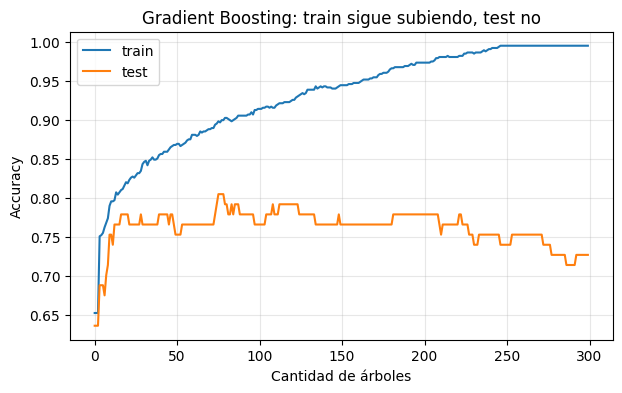

In [24]:
gb_largo = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0)
gb_largo.fit(X_train, T_train)

# staged_predict devuelve la predicción después de cada árbol
acc_train = [accuracy_score(T_train, p) for p in gb_largo.staged_predict(X_train)]
acc_test  = [accuracy_score(T_test, p)  for p in gb_largo.staged_predict(X_test)]

plt.figure(figsize=(7, 4))
plt.plot(acc_train, label="train")
plt.plot(acc_test, label="test")
plt.xlabel("Cantidad de árboles"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Gradient Boosting: train sigue subiendo, test no")
plt.show()

**Parámetros principales de `GradientBoostingClassifier`:**
| Parámetro | Para qué sirve |
|---|---|
| `n_estimators` | Cantidad de árboles (demasiados → sobreajuste). |
| `learning_rate` | Cuánto aporta cada árbol. Más chico = más lento pero más estable. |
| `max_depth` | Profundidad de cada árbol (típico 3 a 8). |
| `loss='log_loss'` | Función de pérdida para clasificación. |

## XGBoost y LightGBM
LightGBM y XGBoost son evoluciones avanzadas de Gradient Boosting, diseñadas para ser mucho más rápidas, escalar con grandes volúmenes de datos y ofrecer un rendimiento superior. Ambas resuelven el problema del Gradient Boosting tradicional, que suele ser lento con muchos datos.

### 1. XGBoost (`XGBClassifier`) — *eXtreme Gradient Boosting*
- Es la librería más famosa en competencias de ciencia de datos (Kaggle).
- **¿Cómo funciona?** Optimiza el Gradient Boosting agregando **regularización** (mecanismos que evitan que el modelo memorice los datos o haga overfitting).
- **Crecimiento de árboles:** por niveles (*level-wise*), evaluando todos los nodos del nivel antes de pasar al siguiente.
- **Fortalezas:** muy preciso, robusto ante el overfitting y maneja bien valores nulos (NaN).
- ⚠️ Necesita que las clases sean 0, 1, 2, ... (en diabetes ya lo son).

### 2. LightGBM (`LGBMClassifier`)
- Desarrollada por Microsoft, optimizada para **velocidad** y **bajo consumo de memoria**.
- **¿Cómo funciona?** En lugar de analizar punto por punto, agrupa los valores continuos en contenedores (*binning*), lo que reduce mucho el cálculo.
- **Crecimiento de árboles:** por hojas (*leaf-wise*), expandiendo solo la hoja con mayor error.
- **Fortalezas:** mucho más rápido que XGBoost en datasets grandes.

In [25]:
# Si no están instaladas: !pip install xgboost lightgbm
from xgboost import XGBClassifier
import lightgbm as lgb

xgb = XGBClassifier(
    n_estimators=100,     # Número de árboles
    learning_rate=0.1,    # Tasa de aprendizaje
    max_depth=6,          # Profundidad máxima de cada árbol
    random_state=42
)
xgb.fit(X_train, T_train)
print("Accuracy XGBoost :", round(accuracy_score(T_test, xgb.predict(X_test)), 3))

lgbm = lgb.LGBMClassifier(
    n_estimators=100,     # Número de árboles
    learning_rate=0.1,    # Tasa de aprendizaje
    num_leaves=31,        # Cantidad máxima de hojas (controla la complejidad)
    random_state=42,
    verbose=-1
)
lgbm.fit(X_train, T_train)
print("Accuracy LightGBM:", round(accuracy_score(T_test, lgbm.predict(X_test)), 3))

Accuracy XGBoost : 0.753
Accuracy LightGBM: 0.779


## Resumen comparativo para tus apuntes

| Característica        | XGBoost (XGBClassifier)                                                                                                              | LightGBM (LGBMClassifier)                                                                                                    |
| :-------------------- | :----------------------------------------------------------------------------------------------------------------------------------- | :--------------------------------------------------------------------------------------------------------------------------- |
| **Estrategia de árbol** | Por niveles (level-wise), evaluando todos los nodos del nivel antes de pasar al siguiente.                                          | Por hojas (leaf-wise), expandiendo únicamente la hoja que tenga el mayor error.                                               |
| **Velocidad**         | Rápida                                                                                                                               | Muy rápida (ideal para datasets grandes)                                                                                     |
| **Uso de Memoria**    | Moderado                                                                                                                             | Bajo                                                                                                                         |
| **Riesgo de Overfitting** | Menor (gracias a su regularización)                                                                                                  | Mayor en datasets muy pequeños (< 10,000 filas)                                                                              |
| **Creador**           | Tianqi Chen / DMLC                                                                                                                   | Microsoft                                                                                                                    |

# Stacking

- Usa **varios modelos de distinto tipo**: árboles, regresión logística, SVM, Naïve Bayes, KNN, redes neuronales, etc. Se los llama estimadores **"base"** o **"débiles"**.
- Introduce el **meta-aprendizaje**: un modelo que **aprende lo aprendido** por los demás.
- El **meta-estimador** aprende **a partir de las predicciones** de los modelos base.

```


               ┌──────────────────────────────┐
               │    DATOS DE ENTRADA (X)      │
               └──────────────┬───────────────┘
                              │
         ┌────────────────────┼────────────────────┐
         ▼                    ▼                    ▼
┌──────────────────┐ ┌──────────────────┐ ┌──────────────────┐
│ DecisionTree (bl1)│ │  KNeighbors (bl2)│ │ LogisticReg(bl3) │  <- Nivel 1 (Base)
└────────┬─────────┘ └────────┬─────────┘ └────────┬─────────┘
         │                    │                    │
         │ Predicción 1       │ Predicción 2       │ Predicción 3
         └────────────────────┼────────────────────┘
                              │
                              ▼
               ┌──────────────────────────────┐
               │  NUEVAS FEATURES / VOTOS     │
               └──────────────┬───────────────┘
                              │
                              ▼
               ┌──────────────────────────────┐
               │ RandomForest (Meta-modelo)   │  <- Nivel 2 (Final)
               └──────────────┬───────────────┘
                              │
                              ▼
               ┌──────────────────────────────┐
               │      PREDICCIÓN FINAL        │
               └──────────────────────────────┘

```

### ¿Cómo funciona?
1. Todos los modelos base aprenden **de forma independiente**.
2. Se arma un **nuevo dataset** con las predicciones de cada modelo (una columna por modelo).
3. El **meta-estimador** se entrena con ese nuevo dataset para predecir la clase.
   Puede ser cualquier modelo, **¡incluso otro ensamble!**

Armamos ese nuevo dataset a mano con diabetes, igual que la tabla de la clase:

In [26]:
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

modelos_base = {
    "Pred_RL":  LogisticRegression(max_iter=1000),
    "Pred_RF":  RandomForestClassifier(n_estimators=100, random_state=0),
    "Pred_KNN": KNeighborsClassifier(n_neighbors=5),
    "Pred_NB":  GaussianNB(),
}

nuevo_dataset = pd.DataFrame(index=X_train.index)
for nombre, m in modelos_base.items():
    # cross_val_predict: cada fila la predice un modelo que NO la vio al entrenar
    nuevo_dataset[nombre] = cross_val_predict(m, X_train, T_train, cv=5, method="predict_proba")[:, 1]
nuevo_dataset["T"] = T_train

nuevo_dataset.head().round(3)

,Pred_RL,Pred_RF,Pred_KNN,Pred_NB,T
260,0.788,0.88,1.0,0.828,0
51,0.092,0.03,0.2,0.020,0
564,0.094,0.24,0.2,0.048,0
108,0.106,0.12,0.0,0.031,0
319,0.798,0.41,0.6,0.921,1


In [27]:
# El meta-estimador aprende con esas columnas
meta = LogisticRegression().fit(nuevo_dataset.drop(columns="T"), nuevo_dataset["T"])
print("¿Cuánto confía el meta-estimador en cada modelo base? (coeficientes)")
print(pd.Series(meta.coef_[0], index=list(modelos_base)).round(2))

¿Cuánto confía el meta-estimador en cada modelo base? (coeficientes)
Pred_RL     1.88
Pred_RF     2.45
Pred_KNN    0.23
Pred_NB     0.47
dtype: float64


> **¿Por qué `cross_val_predict` y no predecir directo?** Si un modelo predice sobre los mismos datos con los que entrenó, sus predicciones son "demasiado buenas" (hace trampa). El meta-estimador aprendería a confiar en el que más memorizó. Por eso se usa **validación cruzada**: es lo que controla el parámetro `cv`.

### Stacking con scikit-learn

In [28]:

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# 1. Definir los estimadores base (Modelos de Nivel 1)
base_learners = [
    ('bl1', DecisionTreeClassifier(max_depth=4)),
    ('bl2', KNeighborsClassifier(n_neighbors=5)),
    ('bl3', LogisticRegression())
]

# 2. Configurar el StackingClassifier con el meta-modelo (Nivel 2)
stck = StackingClassifier(
    estimators=base_learners,
    final_estimator=RandomForestClassifier(n_estimators=100, random_state=42),
    cv=5 # Utiliza validación cruzada interna para entrenar el meta-modelo sin overfitting
)

# 3. Entrenar el modelo apilado
model = stck.fit(X_train, T_train)

# 4. Obtener las probabilidades de cada clase para el conjunto de prueba
probabilidades = model.predict_proba(X_test)
print("Probabilidades predichas por el StackingClassifier:")
print(probabilidades)

Probabilidades predichas por el StackingClassifier:
[[0.38 0.62]
 [0.66 0.34]
 [1.   0.  ]
 [0.8  0.2 ]
 [0.18 0.82]
 [1.   0.  ]
 [0.98 0.02]
 [0.86 0.14]
 [0.92 0.08]
 [0.48 0.52]
 [0.72 0.28]
 [0.82 0.18]
 [1.   0.  ]
 [0.54 0.46]
 [1.   0.  ]
 [0.1  0.9 ]
 [0.97 0.03]
 [0.79 0.21]
 [0.81 0.19]
 [1.   0.  ]
 [0.9  0.1 ]
 [0.44 0.56]
 [0.54 0.46]
 [0.16 0.84]
 [1.   0.  ]
 [0.82 0.18]
 [0.14 0.86]
 [0.92 0.08]
 [0.77 0.23]
 [0.23 0.77]
 [0.09 0.91]
 [0.83 0.17]
 [0.88 0.12]
 [0.76 0.24]
 [0.9  0.1 ]
 [0.53 0.47]
 [0.42 0.58]
 [0.31 0.69]
 [1.   0.  ]
 [0.97 0.03]
 [0.38 0.62]
 [0.84 0.16]
 [0.64 0.36]
 [0.96 0.04]
 [0.77 0.23]
 [0.52 0.48]
 [0.37 0.63]
 [0.92 0.08]
 [0.8  0.2 ]
 [0.59 0.41]
 [0.72 0.28]
 [0.47 0.53]
 [0.85 0.15]
 [1.   0.  ]
 [0.17 0.83]
 [1.   0.  ]
 [0.57 0.43]
 [0.75 0.25]
 [0.45 0.55]
 [0.6  0.4 ]
 [0.81 0.19]
 [0.68 0.32]
 [0.56 0.44]
 [0.11 0.89]
 [0.01 0.99]
 [0.26 0.74]
 [0.3  0.7 ]
 [0.93 0.07]
 [0.29 0.71]
 [0.25 0.75]
 [0.21 0.79]
 [1.   0.  ]
 [1.   0.  ]

In [29]:
print("Accuracy Stacking:", round(accuracy_score(T_test, model.predict(X_test)), 3))
print("\nCada modelo base por separado:")
for nombre, modelo_base in model.named_estimators_.items():
    print(f"  {nombre}: {accuracy_score(T_test, modelo_base.predict(X_test)):.3f}")

Accuracy Stacking: 0.675

Cada modelo base por separado:
  bl1: 0.727
  bl2: 0.701
  bl3: 0.792


> El Stacking **no siempre gana**: depende de qué modelos base elijas. Acá KNN y Regresión Logística reciben los datos sin escalar (las columnas tienen escalas muy distintas, ej. Insulin vs DiabetesPedigreeFunction), y eso los perjudica.

### Parámetros `cv` y `passthrough`
- `cv` → cantidad de partes de la validación cruzada para armar el nuevo dataset.
- `passthrough=True` → el meta-estimador recibe **las predicciones + las columnas originales**. Con `False` (default) solo recibe las predicciones.

In [30]:
stck_cv = StackingClassifier(estimators=base_learners,
                             final_estimator=RandomForestClassifier(random_state=42),
                             cv=10,
                             passthrough=True)
stck_cv.fit(X_train, T_train)
print("Accuracy (cv=10, passthrough=True):", round(accuracy_score(T_test, stck_cv.predict(X_test)), 3))

# ¿Cuántas columnas recibe el meta-estimador?
print("Columnas que ve el meta-estimador:", stck_cv.transform(X_test).shape[1],
      "= 3 predicciones +", len(feature_cols), "atributos originales")

Accuracy (cv=10, passthrough=True): 0.714
Columnas que ve el meta-estimador: 11 = 3 predicciones + 8 atributos originales


### Stacking de múltiples capas — *¿Cómo está conformado este stacking?*

El `final_estimator` de `stck_1` es **otro stacking** (`stck_2`). Queda así:

```
                  Datos (X)
                     │
        ┌────────────┴────────────┐
   Árbol (bl1)              Reg. Logística (bl2)      ◄ CAPA 1
        └────────────┬────────────┘
             predicciones de la capa 1
                     │
        ┌────────────┴────────────┐
     KNN (bl3)            Reg. Lineal (bl4)           ◄ CAPA 2
        └────────────┬────────────┘
             predicciones de la capa 2
                     │
               Random Forest                          ◄ CAPA 3 (meta-estimador final)
                     │
              Predicción final
```

- La capa 2 **no ve los datos originales**, solo las predicciones de la capa 1.
- ⚠️ `LinearRegression` es un modelo de **regresión** (predice un número, no una clase). scikit-learn lo acepta, pero en clasificación lo correcto sería `LogisticRegression`.

In [31]:
from sklearn.linear_model import LinearRegression

base_learners_1 = [('bl1', DecisionTreeClassifier(max_depth=4)),
                   ('bl2', LogisticRegression(max_iter=1000))]
base_learners_2 = [('bl3', KNeighborsClassifier(n_neighbors=5)),
                   ('bl4', LinearRegression())]

stck_2 = StackingClassifier(estimators=base_learners_2, final_estimator=RandomForestClassifier())
stck_1 = StackingClassifier(estimators=base_learners_1, final_estimator=stck_2)
model = stck_1.fit(X_train, T_train)

print("Accuracy stacking de 3 capas:", round(accuracy_score(T_test, model.predict(X_test)), 3))
print("Capa 1:", list(model.named_estimators_))
print("Capa 2:", list(model.final_estimator_.named_estimators_))
print("Capa 3:", type(model.final_estimator_.final_estimator_).__name__)

Accuracy stacking de 3 capas: 0.623
Capa 1: ['bl1', 'bl2']
Capa 2: ['bl3', 'bl4']
Capa 3: RandomForestClassifier


# 6. Comparación de todos los modelos

Con **una sola división** train/test el resultado depende mucho del azar (el test tiene solo 77 pacientes).
Por eso repetimos **10 veces** cambiando el `random_state` y calculamos **promedio** e **intervalo de confianza del 95%**:

$$IC_{95\%} = \text{promedio} \pm t \cdot \frac{\text{desvío}}{\sqrt{n}} \qquad (n = 10,\ t \approx 2{,}26)$$

**Métricas** (repaso):
- **Accuracy:** % de aciertos.
- **Precision:** de los que predije "diabetes", cuántos realmente la tienen.
- **Recall:** de los que tienen diabetes, cuántos detecté.
- **F1:** combina precision y recall.
- **AUC-ROC:** qué tan bien separa las clases usando las probabilidades (1 = perfecto, 0,5 = azar).

In [32]:
from scipy import stats
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def media_ic95(valores):
    media = np.mean(valores)
    margen = stats.t.ppf(0.975, len(valores) - 1) * np.std(valores, ddof=1) / np.sqrt(len(valores))
    return media, margen

modelos = {
    "Árbol":             lambda: DecisionTreeClassifier(),
    "Random Forest":     lambda: RandomForestClassifier(n_estimators=200),
    "AdaBoost":          lambda: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200),
    "Gradient Boosting": lambda: GradientBoostingClassifier(n_estimators=50, max_depth=3),
    "XGBoost":           lambda: XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3),
    "Stacking":          lambda: StackingClassifier(estimators=base_learners,
                                                    final_estimator=RandomForestClassifier()),
}

resultados = []
for seed in range(10):
    Xtr, Xte, Ttr, Tte = train_test_split(X, T, test_size=0.1, random_state=seed)
    for nombre, crear in modelos.items():
        m = crear().fit(Xtr, Ttr)
        pred = m.predict(Xte)
        resultados.append({"modelo": nombre,
                           "accuracy":  accuracy_score(Tte, pred),
                           "precision": precision_score(Tte, pred),
                           "recall":    recall_score(Tte, pred),
                           "f1":        f1_score(Tte, pred),
                           "auc":       roc_auc_score(Tte, m.predict_proba(Xte)[:, 1])})
resultados = pd.DataFrame(resultados)

tabla = resultados.groupby("modelo").agg(lambda v: "{:.3f} ± {:.3f}".format(*media_ic95(v)))
tabla

,accuracy,precision,recall,f1,auc
modelo,,,,,
AdaBoost,0.758 ± 0.037,0.681 ± 0.044,0.622 ± 0.045,0.649 ± 0.041,0.838 ± 0.037
Gradient Boosting,0.748 ± 0.041,0.675 ± 0.055,0.579 ± 0.062,0.622 ± 0.054,0.836 ± 0.033
Random Forest,0.760 ± 0.030,0.683 ± 0.045,0.619 ± 0.063,0.646 ± 0.045,0.830 ± 0.034
Stacking,0.744 ± 0.032,0.663 ± 0.047,0.582 ± 0.074,0.616 ± 0.054,0.796 ± 0.028
XGBoost,0.748 ± 0.031,0.662 ± 0.037,0.614 ± 0.066,0.633 ± 0.044,0.830 ± 0.028
Árbol,0.709 ± 0.036,0.596 ± 0.065,0.608 ± 0.065,0.598 ± 0.052,0.688 ± 0.042


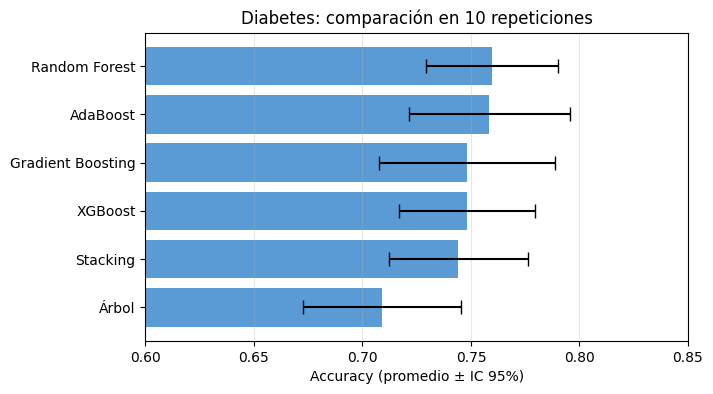

In [33]:
# Gráfico de accuracy con su intervalo de confianza
resumen = resultados.groupby("modelo")["accuracy"].apply(lambda v: pd.Series(media_ic95(v), index=["media", "margen"])).unstack()
resumen = resumen.sort_values("media")
plt.figure(figsize=(7, 4))
plt.barh(resumen.index, resumen["media"], xerr=resumen["margen"], capsize=5, color="#5B9BD5")
plt.xlim(0.6, 0.85); plt.xlabel("Accuracy (promedio ± IC 95%)")
plt.title("Diabetes: comparación en 10 repeticiones"); plt.grid(axis="x", alpha=0.3)
plt.show()

**¿Cómo leer el gráfico?** Si las barras de error de dos modelos **se superponen**, no podemos afirmar que uno sea mejor que el otro. Si **no se superponen**, sí hay una diferencia clara.

# 7. Actividad 2 (dataset *glass*)

> Utilice la base de datos **glass**, separando en 90-10. Entrene un **AdaBoost**, un **Gradient Boosting** y un **Stacking** (con al menos cuatro estimadores base). Calcule e imprima accuracy, precision, recall, f-score y AUC-ROC. Repita los cálculos 10 veces, cambiando el `random_state` en el split. Calcule el promedio e IC 95% de cada métrica. Compare con los de la actividad 1.

**Diferencias con diabetes:**
- *glass* tiene **6 clases** de vidrio (1, 2, 3, 5, 6, 7), no 2.
- Por eso las métricas necesitan `average="macro"` (promedia todas las clases por igual) y el AUC necesita `multi_class="ovr"` (cada clase contra el resto).
- Hay clases con muy pocas muestras (la 6 tiene 9) → usamos `stratify=T` para que todas aparezcan en el test.
- XGBoost necesita las clases como 0, 1, 2, ... → usamos `LabelEncoder`.

In [34]:
from sklearn.preprocessing import LabelEncoder

# Desde internet (o cambiá por la ruta de tu Drive)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/glass.csv"
glass = pd.read_csv(url, header=None,
                    names=["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"])

Xg = glass.drop(columns="Type")
Tg = LabelEncoder().fit_transform(glass["Type"])     # 1,2,3,5,6,7 -> 0,1,2,3,4,5
print(glass.shape)
print(glass["Type"].value_counts().sort_index())

(214, 10)
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


In [35]:
from sklearn.svm import SVC

modelos_glass = {
    "AdaBoost": lambda: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=300),
    "Gradient Boosting": lambda: GradientBoostingClassifier(n_estimators=100, max_depth=3),
    "Stacking": lambda: StackingClassifier(
        estimators=[('arbol', DecisionTreeClassifier(max_depth=5)),     # 4 estimadores base
                    ('knn', KNeighborsClassifier(n_neighbors=5)),
                    ('svm', SVC(probability=True)),
                    ('nb', GaussianNB())],
        final_estimator=LogisticRegression(max_iter=2000)),
}

res_glass = []
for seed in range(10):
    Xtr, Xte, Ttr, Tte = train_test_split(Xg, Tg, test_size=0.1, random_state=seed, stratify=Tg)
    for nombre, crear in modelos_glass.items():
        m = crear().fit(Xtr, Ttr)
        pred = m.predict(Xte)
        res_glass.append({"modelo": nombre,
                          "accuracy":  accuracy_score(Tte, pred),
                          "precision": precision_score(Tte, pred, average="macro", zero_division=0),
                          "recall":    recall_score(Tte, pred, average="macro", zero_division=0),
                          "f1":        f1_score(Tte, pred, average="macro", zero_division=0),
                          "auc":       roc_auc_score(Tte, m.predict_proba(Xte), multi_class="ovr")})
res_glass = pd.DataFrame(res_glass)

print("Promedio ± IC 95% (10 repeticiones):")
res_glass.groupby("modelo").agg(lambda v: "{:.3f} ± {:.3f}".format(*media_ic95(v)))

Promedio ± IC 95% (10 repeticiones):


,accuracy,precision,recall,f1,auc
modelo,,,,,
AdaBoost,0.718 ± 0.076,0.632 ± 0.103,0.628 ± 0.095,0.612 ± 0.094,0.926 ± 0.025
Gradient Boosting,0.759 ± 0.069,0.714 ± 0.102,0.732 ± 0.071,0.708 ± 0.085,0.953 ± 0.012
Stacking,0.700 ± 0.060,0.639 ± 0.098,0.652 ± 0.094,0.635 ± 0.097,0.924 ± 0.022


Para **comparar con la actividad 1**, poné al lado los promedios e IC que obtuviste ahí y fijate si los intervalos se superponen.

# 8. Resumen para repasar

| | **Bagging / Random Forest** | **AdaBoost** | **Gradient Boosting** | **Stacking** |
|---|---|---|---|---|
| Entrenamiento | En paralelo | Secuencial | Secuencial | Base en paralelo + meta-modelo |
| ¿Qué cambia entre modelos? | Las filas (y columnas) que ve cada uno | El **peso** de las muestras | Lo que predice: los **residuos** | El **tipo** de modelo |
| ¿Cómo combina? | Votación | Votación ponderada por α | Suma de los valores de los árboles × learning_rate | Un meta-estimador |
| Modelo base típico | Árbol completo | Árbol de 1 nivel | Árbol de 3 a 8 niveles | Cualquiera |
| ¿Más modelos sobreajusta? | No | Puede | Sí | — |
| Código | `RandomForestClassifier` | `AdaBoostClassifier` | `GradientBoostingClassifier`, `XGBClassifier`, `LGBMClassifier` | `StackingClassifier` |

### Preguntas para autoevaluarte
1. ¿Qué diferencia hay entre bootstrapping y pasting?
   → Bootstrapping elige filas **con** reemplazo; pasting **sin** reemplazo.
2. ¿Qué devuelve `predict_proba` en un Random Forest?
   → La proporción de árboles que votó cada clase.
3. ¿Qué pasa con el peso de una muestra mal clasificada en AdaBoost?
   → Aumenta, para que el siguiente modelo le preste más atención.
4. ¿Qué significa un α alto?
   → Que ese modelo tuvo poco error y su voto pesa más.
5. En Gradient Boosting, ¿qué predice cada nuevo árbol?
   → Los **residuos** (errores) del modelo hasta ese momento.
6. ¿Por qué la Prob inicial del ejemplo es 0,625?
   → Hay 5 muestras de clase 1 sobre 8 en total.
7. ¿Qué hace el meta-estimador en Stacking?
   → Aprende a combinar las predicciones de los modelos base.
8. ¿Para qué sirven `cv` y `passthrough`?
   → `cv`: validación cruzada para armar el nuevo dataset sin trampa. `passthrough=True`: el meta-estimador también recibe las columnas originales.